# 04 · EMT-TF Expression — Geistlinger 2020 HGSOC

The EMT transcription-factor readout is **unconditional** and is the final notebook (Gate 3 = NA, so no
04_correlation / 05_modules). Score a mesenchymal-TF panel (Snail/Zeb/Twist plus FOXC and PRRX families,
per the Kürten lesson) gated on detectable expression, pick the factors most polarised toward the two ends
of the trajectory, and overlay thresholded expressers on the grey manifold in the house categorical style.
Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 5906 | pseudotime 0.0 -> 17.96


In [4]:
# score EMT-TF panel on THIS dataset, gated on detection; derive the end-polarised pair
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03].sort_values('rho_vs_t')
# end-polarised pair: most negative rho = root-end factor, most positive rho = terminus-end factor
early_tf = ok.iloc[0]['TF']    # steepest decline along pseudotime -> peaks at the root
late_tf  = ok.iloc[-1]['TF']   # least declining / most terminus-shifted of the expressed panel
print(f'\nall expressed EMT-TFs decline from the Gast/pSom-high root toward the Crest terminus '
      f'(rho range {ok.rho_vs_t.min():+.2f} to {ok.rho_vs_t.max():+.2f}); '
      f'the panel is a root/mesenchymal readout.')
print(f'derived pair: {early_tf} (root-end, steepest decline) <-> {late_tf} (terminus-end, least declining)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t         end
 PRRX2      0.162       1.372      0.167    -0.354 EARLY(root)
 FOXC1      0.078       0.630      0.089    -0.230 EARLY(root)
  ZEB2      0.108       0.745      0.193    -0.214 EARLY(root)
 SNAI1      0.070       0.504      0.109    -0.199 EARLY(root)
  ZEB1      0.062       0.458      0.081    -0.181 EARLY(root)
 PRRX1      0.041       0.295      0.086    -0.134 EARLY(root)
TWIST1      0.020       0.141      0.015    -0.113 EARLY(root)
 SNAI2      0.032       0.218      0.072    -0.106 EARLY(root)
TWIST2      0.017       0.114      0.026    -0.088 EARLY(root)

all expressed EMT-TFs decline from the Gast/pSom-high root toward the Crest terminus (rho range -0.35 to -0.11); the panel is a root/mesenchymal readout.
derived pair: PRRX2 (root-end, steepest decline) <-> SNAI2 (terminus-end, least declining)


overlay thresholds (upper quartile among expressers): {'PRRX2': 4.782, 'SNAI2': 4.757} | cells shown: {'PRRX2': 239, 'SNAI2': 47}
PRRX2: 16.2% expressing; 239 shown, mean pt of shown = 0.42 (all = 0.47)
SNAI2: 3.2% expressing; 47 shown, mean pt of shown = 0.68 (all = 0.47)
saved expression.pdf


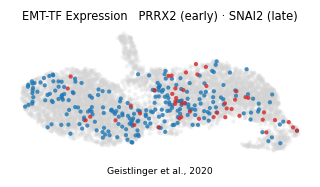

In [5]:
# categorical overlay of thresholded expressers on the grey manifold (house style)
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Geistlinger et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown, '
          f'mean pt of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')